# Agent的基本使用
## 1、Agent中模型的传入方式
### 1.1 传入字符串

In [22]:
from langchain_community.chat_models import ChatZhipuAI
from dotenv import load_dotenv
import os
from rich import print as rprint

# 从.env文件中加载环境变量
load_dotenv(override=True)

ZHIPUAI_API_KEY = os.getenv("ZHIPUAI_API_KEY")
ZHIPUAI_BASE_URL = os.getenv("ZHIPUAI_BASE_URL")

model = ChatZhipuAI(
    model="glm-5.3-flash",
    api_key=ZHIPUAI_API_KEY,
    base_url=ZHIPUAI_BASE_URL,
)

In [23]:
from langchain_community.chat_models import ChatZhipuAI
from langchain.agents import create_agent
from dotenv import load_dotenv

load_dotenv(override=True)

agent = create_agent(model)

print(type(agent))

<class 'langgraph.graph.state.CompiledStateGraph'>


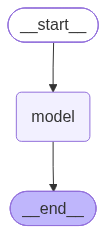

In [25]:
from IPython.display import Image,display
display(Image(agent.get_graph().draw_mermaid_png()))

# 2、如何调用Agent

In [26]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint


agent = create_agent(model=model)

response = agent.invoke({"messages": ["你好"]}) # 默认是HumanMessage
print(type(response))
rprint(response)

<class 'dict'>


{
    'messages': [
        HumanMessage(
            content='你好',
            additional_kwargs={},
            response_metadata={},
            id='cadf6f80-1f65-443d-9abf-5dba076fb56e'
        ),
        AIMessage(
            content='你好！很高兴见到你。我是Z.ai训练的GLM大语言模型，随时准备为你提供帮助。\n\n有什么我能为你解答
或协助的问题吗？无论是寻找信息、解决问题，还是简单聊天，我都很乐意与你交流。',
            additional_kwargs={},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 250,
                    'completion_tokens_details': {'reasoning_tokens': 200},
                    'prompt_tokens': 13,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 263
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'stop'
            },
            id='lc_run--01a14893-6929-7ff2-96b7-ecd3a3f9bc8b-0',
            tool_calls=[],
            invalid_tool_calls=[]
        )
    ]
}

举例2

In [27]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint


agent = create_agent(model=model)

response = agent.invoke( {
    "messages": [
        {"role": "system", "content": "你是一个小学数学老师，耐心，幽默，讲解深入浅出"},
        {"role": "user", "content": "100加上50等于多少？"}
    ]}) 
print(type(response))
rprint(response)

<class 'dict'>


{
    'messages': [
        SystemMessage(
            content='你是一个小学数学老师，耐心，幽默，讲解深入浅出',
            additional_kwargs={},
            response_metadata={},
            id='fd2fc408-0920-40a1-ae53-2dad510cdc4c'
        ),
        HumanMessage(
            content='100加上50等于多少？',
            additional_kwargs={},
            response_metadata={},
            id='e6404ed3-e8ea-411b-8d7c-3db441fc4da9'
        ),
        AIMessage(
            content='哈哈，这个问题问得好！🎉\n\n**100 + 50 = 150**\n\n来，我们用买零食的方式想象一下：\n\n想象你有
**100元** 零花钱 💰\n妈妈又给了你 **50元**（妈妈真好！）\n\n那你现在口袋里一共有多少钱呢？\n\n```\n  100\n+  
50\n—————\n  
150\n```\n\n看，100再往后数50个，就到150啦！💰💰💰\n\n**小口诀**：整十数相加很简单，先把十位加起来（10个十 + 5个十 
= 15个十），后面补个0，就是150！\n\n怎么样，是不是像数糖果一样简单？😄 还有别的题目要挑战吗？',
            additional_kwargs={},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 275,
                    'completion_tokens_details': {'reasoning_tokens': 115},
                    'prompt_tokens': 33,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 308
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'stop'
            },
            id='lc_run--01a14897-96a1-7530-9c18-a23b8eda382b-0',
            tool_calls=[],
            invalid_tool_calls=[]
        )
    ]
}

# 3、如何绑定工具，调用工具

举例1：绑定一个自定义工具

In [28]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os

from sympy import content
load_dotenv(override=True)
from rich import print as rprint

def get_weather(city:str):
    '''查询天气的工具
    
    Args:
        city:具体城市
    '''
    return(f'{city}天气晴朗,温度15℃')


agent = create_agent(
    model=model,
    tools=[get_weather]
)


res = agent.invoke({
    'messages':[
        {'role':'system','content':'你是一个查询天气的助手，根据用户的提问查询天气，如果问题跟天气无关，你可以说：我不清楚这个问题的答案'},
        {'role':'user','content':'北京的天气如何？'}
    ]
})

rprint(res)

{
    'messages': [
        SystemMessage(
            content='你是一个查询天气的助手，根据用户的提问查询天气，如果问题跟天气无关，你可以说：我不清楚这个问题
的答案',
            additional_kwargs={},
            response_metadata={},
            id='6a69edd2-3fe7-4f29-94fc-9f62048c686b'
        ),
        HumanMessage(
            content='北京的天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='0f96c191-69a2-441f-b0d0-6db721066248'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {'arguments': '{"city":"北京"}', 'name': 'get_weather'},
                        'id': 'call_-7162281449855384240',
                        'index': 0,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 38,
                    'completion_tokens_details': {'reasoning_tokens': 26},
                    'prompt_tokens': 193,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 231
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'tool_calls'
            },
            id='lc_run--01a148a0-f7fb-7163-9657-857b615da69b-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_-7162281449855384240',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[]
        ),
        ToolMessage(
            content='北京天气晴朗,温度15℃',
            name='get_weather',
            id='1bd61379-373e-4120-8a75-ce7482504e8c',
            tool_call_id='call_-7162281449855384240'
        ),
        AIMessage(
            content='北京今天的天气晴朗，温度为15℃，天气很不错，适合外出活动。🌤️',
            additional_kwargs={},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 21,
                    'completion_tokens_details': {'reasoning_tokens': 0},
                    'prompt_tokens': 207,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 228
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'stop'
            },
            id='lc_run--01a148a1-0ad8-71a1-99df-944912bd0116-0',
            tool_calls=[],
            invalid_tool_calls=[]
        )
    ]
}

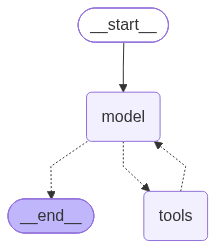

In [29]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

### 举例2：调用langchain内置的工具


In [33]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os

from langchain_tavily import TavilySearch
from sympy import content
load_dotenv(override=True)
from rich import print as rprint

#使用内置的工具
web_search = TavilySearch(
    max_results = 2,
    Tavily_key = os.getenv('TAVILY_API_KEY'),
)


agent = create_agent(
    model=model,
    tools=[web_search]
)


res = agent.invoke({
    'messages':[
        {'role':'user','content':'请问2024年足球世界杯有哪些参赛队？'}
    ]
})

rprint(res)

{
    'messages': [
        HumanMessage(
            content='请问2024年足球世界杯有哪些参赛队？',
            additional_kwargs={},
            response_metadata={},
            id='9998f923-ca97-4b59-8e73-5106b13813fd'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {
                            'arguments': '{"query":"2024年足球世界杯 参赛队","search_depth":"basic"}',
                            'name': 'tavily_search'
                        },
                        'id': 'call_-7162271691689683826',
                        'index': 0,
                        'type': 'function'
                    },
                    {
                        'function': {
                            'arguments': '{"query":"下一届世界杯 2026年 参赛球队 
亚洲区预选赛","search_depth":"basic"}',
                            'name': 'tavily_search'
                        },
                        'id': 'call_-7162271691689683825',
                        'index': 1,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 218,
                    'completion_tokens_details': {'reasoning_tokens': 154},
                    'prompt_tokens': 1650,
                    'prompt_tokens_details': {'cached_tokens': 1600},
                    'total_tokens': 1868
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'tool_calls'
            },
            id='lc_run--01a148ad-d45f-75e3-873c-b2164c1a4d7a-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {'query': '2024年足球世界杯 参赛队', 'search_depth': 'basic'},
                    'id': 'call_-7162271691689683826',
                    'type': 'tool_call'
                },
                {
                    'name': 'tavily_search',
                    'args': {'query': '下一届世界杯 2026年 参赛球队 亚洲区预选赛', 'search_depth': 'basic'},
                    'id': 'call_-7162271691689683825',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[]
        ),
        ToolMessage(
            content='{"query": "2024年足球世界杯 参赛队", "follow_up_questions": null, "answer": null, "images": 
[], "results": [{"url": 
"https://zh.wikipedia.org/zh-hans/2024%E5%B9%B4%E6%AD%90%E6%B4%B2%E8%B6%B3%E7%90%83%E9%8C%A6%E6%A8%99%E8%B3%BD", 
"title": "2024年欧洲足球锦标赛 - 维基百科，自由的百科全书", "content": "## 
参赛球队\\n\\n[编辑]\\n\\n此届欧锦赛有很多重返欧锦赛的队伍以及一支第一次参加的新丁，塞尔维亚、阿尔巴尼亚、罗马尼亚
以及斯洛文尼亚都重新参加欧锦赛，格鲁吉亚将首次亮相欧锦赛。\\n\\n### 
外围赛\\n\\n[编辑]\\n\\n主条目：2024年欧洲国家杯外围赛 [...] | 决赛圈 |  1960 法国  1964 西班牙  1968 意大利  1972 
比利时  1976 南斯拉夫  1980 意大利  1984 法国  1988 西德  1992 瑞典  1996 英格兰  2000 比利时/荷兰  2004 葡萄牙  
2008 奥地利/瑞士  2012 波兰/乌克兰  2016 法国  2020 合办  2024 德国  2028 爱尔兰/英国  2032 意大利/土耳其 |\\n| 
预选赛 |  1960  1964  1968  1972  1976  1980  1984  1988  1992  1996  2000  2004  2008  2012  2016  2020  2024  
2028 |\\n| 决赛 |  1960  1964  1968  1972  1976  1980  1984  1988  1992  1996  2000  2004  2008  2012  2016  2020  
2024 | [...] 瑞士 雷莫·弗罗伊勒\\n 瑞士 鲁本·巴尔加斯\\n 瑞士 罗马诺·施密德\\n 土耳其 
凯雷姆·阿克图科格鲁（英语：Kerem Aktürkoğlu）\\n 土耳其 阿尔达·居莱尔\\n 土耳其 梅尔特·米尔德尔（英语：Mert 
Müldür）\\n 土耳其 哈坎·恰尔汗奥卢\\n 土耳其 堅克·托松\\n 土耳其 萨梅特·阿卡伊丁（英语：Samet Akaydin）\\n 乌克兰 
米科拉·沙帕伦科（英语：Mykola Shaparenko）\\n 乌克兰 罗曼·亚列姆丘克", "score": 0.6796259, "raw_content": null, 
"id": "cb9b2d-00"}, {"url": 
"https://baike.baidu.com/item/2024%E5%B9%B4%E5%9B%BD%E9%99%85%E4%B8%AD%E4%BD%93%E8%81%94%E8%B6%B3%E7%90%83%E4%B8%96
%E7%95%8C%E6%9D%AF/64004539", "title": "2024年国际中体联足球世界杯", "content": "展开全部\\n\\nImage 
4\\n\\n2024年国际中体联足球世界杯的概述图（1张）\\n\\n词条统计\\n\\n浏览次数：\\n\\n编辑次数：16次历史版本\\n\\n最
近更新：\\n\\n动捕技术宅\\n\\n（2026-10-11）\\n\\n1 赛事简介2 赛事申办3 赛事筹备4 参赛阵容5 赛事进程6 赛事数据7 
奖牌榜8 赛事文化9 赛事保障10 赛事影响\\n\\nImage 5: 
图片\\n\\n2024年国际中体联足球世界杯\\n\\n选择朗读音色\\n\\nImage 6: 成熟女声\\n\\n成熟

### 举例3：绑定多个工具，并调用

In [34]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv()

@tool(parse_docstring=True)
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    return f"{city}今天天气挺好"

@tool(parse_docstring=True)
def get_news():
    """
    新闻查询工具
    """
    return "近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧手机成“香饽饽”。"

agent = create_agent(
    model,
    tools=[get_weather, get_news]
)
response = agent.invoke({
    "messages": ["你好，杭州今天的天气如何？今天有哪些新闻？"]
})

rprint(response) 

{
    'messages': [
        HumanMessage(
            content='你好，杭州今天的天气如何？今天有哪些新闻？',
            additional_kwargs={},
            response_metadata={},
            id='85cee3aa-bd56-4ad3-be04-642f9c50c17f'
        ),
        AIMessage(
            content='你好！我来帮你查询杭州的天气和今日新闻。',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {'arguments': '{"city":"杭州"}', 'name': 'get_weather'},
                        'id': 'call_-7162291208021080203',
                        'index': 0,
                        'type': 'function'
                    },
                    {
                        'function': {'arguments': '{}', 'name': 'get_news'},
                        'id': 'call_-7162291208021080202',
                        'index': 1,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 59,
                    'completion_tokens_details': {'reasoning_tokens': 31},
                    'prompt_tokens': 197,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 256
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'tool_calls'
            },
            id='lc_run--01a148b9-4274-7c12-8880-d77c4df9e25c-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_-7162291208021080203',
                    'type': 'tool_call'
                },
                {'name': 'get_news', 'args': {}, 'id': 'call_-7162291208021080202', 'type': 'tool_call'}
            ],
            invalid_tool_calls=[]
        ),
        ToolMessage(
            content='杭州今天天气挺好',
            name='get_weather',
            id='aab13980-d6b4-4ff0-8c1d-e3106eb871a3',
            tool_call_id='call_-7162291208021080203'
        ),
        ToolMessage(
            content='近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍
上涨，旧手机成“香饽饽”。',
            name='get_news',
            id='fa93fd42-52ae-49b7-b7f4-7580444b375e',
            tool_call_id='call_-7162291208021080202'
        ),
        AIMessage(
            content='查询结果如下：\n\n**🌤️ 杭州天气**\n杭州今天天气挺好，适合外出活动。\n\n**📰 
今日新闻**\n近期，受全球存储芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来"火热潮"，回收价格普遍上涨，旧
手机成了"香饽饽"。\n\n如果你还想了解其他城市的天气或更多信息，随时告诉我！',
            additional_kwargs={},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'completion_tokens_details': {'reasoning_tokens': 24},
                    'prompt_tokens': 261,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 366
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'stop'
            },
            id='lc_run--01a148b9-63fe-7250-8ed1-c757cfef7614-0',
            tool_calls=[],
            invalid_tool_calls=[]
        )
    ]
}

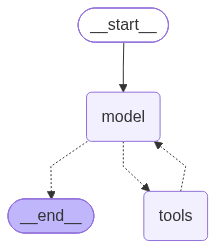

In [35]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

## 4、重试机制

In [38]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

flag = 0

@tool
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    global flag
    flag += 1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}今天天气挺好"


messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

rprint(response)

for msg in response["messages"]:
    msg.pretty_print()

{
    'messages': [
        SystemMessage(
            content="\n    你是一个天气助手。\n    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，\n    
说明是临时故障，不要立即放弃；\n    你应再次调用同一个工具，最多重试 3 次。\n    如果 3 
次后仍失败，再向用户说明服务暂时不可用。\n    ",
            additional_kwargs={},
            response_metadata={},
            id='98e0984c-32ba-4c62-be82-c28dd8ab3efc'
        ),
        HumanMessage(
            content='你好，杭州今天的天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='cacd96c3-e217-40e1-8d0d-3fcf46958a88'
        ),
        AIMessage(
            content='你好！我来帮你查询杭州今天的天气。',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {'arguments': '{"city":"杭州"}', 'name': 'get_weather'},
                        'id': 'call_-7162277361046513260',
                        'index': 0,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 76,
                    'completion_tokens_details': {'reasoning_tokens': 55},
                    'prompt_tokens': 240,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 316
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'tool_calls'
            },
            id='lc_run--01a148f6-ef1c-7310-951e-77f08df7f2f1-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_-7162277361046513260',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[]
        ),
        ToolMessage(
            content='TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试',
            name='get_weather',
            id='8be511b1-58bd-4f26-946c-1e30cdc40235',
            tool_call_id='call_-7162277361046513260'
        ),
        AIMessage(
            content='天气服务出现临时故障，我再试一次。',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {'arguments': '{"city":"杭州"}', 'name': 'get_weather'},
                        'id': 'call_-7162273615835031921',
                        'index': 0,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 57,
                    'completion_tokens_details': {'reasoning_tokens': 35},
                    'prompt_tokens': 271,
                    'prompt_tokens_details': {'cached_tokens': 0},
                    'total_tokens': 328
                },
                'model_name': 'glm-5.3-flash',
                'finish_reason': 'tool_calls'
            },
            id='lc_run--01a148f7-02ed-7d82-a29c-ced8c4e25490-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_-7162273615835031921',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[]
        ),
        ToolMessage(
            content='TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试',
            name='get_weather',
            id='10762435-3732-4746-9206-3431804f079e',
            tool_call_id='call_-7162273615835031921'
        ),
        AIMessage(
            content='还是不行，我再尝试最后一次。',
            additional_kwargs={
                'tool_calls': [
                    {
                        'function': {'arguments': '{"city":"杭州"}', 'name': 'get_weather'},
                        'id': 'call_-7162272344524714669',
                        'index': 0,
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': 

================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================

你好！我来帮你查询杭州今天的天气。
Tool Calls:
  get_weather (call_-7162277361046513260)
 Call ID: call_-7162277361046513260
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================

天气服务出现临时故障，我再试一次。
Tool Calls:
  get_weather (call_-7162273615835031921)
 Call ID: call_-7162273615835031921
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后